# BigMart Sales: Modelling

**Goal:** predict `Item_Outlet_Sales` for the 5,681 rows in `test.csv` and submit them to the Analytics Vidhya leaderboard.
We use the clean data from `bigmart_eda_cleaning.ipynb`. The target is a number, so we judge models with **RMSE** (the leaderboard metric), plus MAE and R².

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df = pd.read_csv("bigmart_clean.csv")       # clean data with the group names (from the EDA notebook)
enc = pd.read_csv("bigmart_encoded.csv")    # the same rows, one-hot encoded (from the EDA notebook)
test = pd.read_csv("test.csv")              # the rows we have to predict (no sales column)
print("clean:", df.shape, "| encoded:", enc.shape, "| test:", test.shape)

clean: (8523, 12) | encoded: (8523, 35) | test: (5681, 11)


---
**Step 1 takeaway**
- **What we did:** Loaded the clean data, the encoded data and the test file.
- **Why:** The EDA notebook already cleaned and encoded the training data, so we start from there.
- **What we learnt:** 8,523 training rows and 5,681 test rows to predict.
---

## Step 2: Train / validation split

We keep 20% of the training rows aside as a **validation set**. The models never see these rows while learning, so the validation error tells us how well a model does on new data (like the lab: `test_size=0.2, random_state=42`).

No scaling: a linear regression gives the same predictions with or without it, and a tree only compares each value with a threshold. Scaling matters for models that measure distances or shrink coefficients (SVM, KNN, Ridge), which we don't use.

In [3]:
X = enc.drop(columns=["Item_Outlet_Sales"])
y = enc["Item_Outlet_Sales"]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, "| validation:", X_val.shape)

results = []   # we add each model's scores here, then compare them in Step 7

train: (6818, 34) | validation: (1705, 34)


---
**Step 2 takeaway**
- **What we did:** Split the training data 80/20 into train and validation.
- **Why:** To measure each model on rows it has not seen, so we can spot overfitting.
- **What we learnt:** 6,818 rows to learn from and 1,705 rows to test on.
---

## Step 3: Model 1: Linear regression on all columns (baseline)

In [4]:
lr = LinearRegression()
lr.fit(X_train, y_train)
pred = lr.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, pred))
mae = mean_absolute_error(y_val, pred)
r2 = r2_score(y_val, pred)
print(f"RMSE: {rmse:.1f} | MAE: {mae:.1f} | R²: {r2:.3f}")
results.append({"Model": "1. Linear regression, all columns", "RMSE": rmse, "MAE": mae, "R2": r2})

RMSE: 1069.1 | MAE: 791.6 | R²: 0.579


In [5]:
# The EDA showed sales are right-skewed, so we also try predicting log(sales)
# and turning the prediction back into sales with np.exp()
lr_log = LinearRegression()
lr_log.fit(X_train, np.log(y_train))
pred_log = np.exp(lr_log.predict(X_val))
print(f"RMSE with log target: {np.sqrt(mean_squared_error(y_val, pred_log)):.1f}")

RMSE with log target: 1085.4


---
**Step 3 takeaway**
- **What we did:** Fitted a linear regression on all 34 input columns, and tried a log-transformed target.
- **Why:** A simple baseline that every other model has to beat.
- **What we learnt:** RMSE is about 1,069 on the validation set. The log target is worse (about 1,085), so we keep the normal target.
---

## Step 4: Model 2: Decision tree

A tree that grows too deep memorises the training rows (overfitting). We try depths 2 to 10 and watch the train and validation errors.
`min_samples_leaf=50` means every final leaf must hold at least 50 rows, so the tree can't make a rule for just a few rows.

In [6]:
for depth in range(2, 11):
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=50, random_state=42)
    tree.fit(X_train, y_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, tree.predict(X_train)))
    val_rmse = np.sqrt(mean_squared_error(y_val, tree.predict(X_val)))
    print(f"depth {depth} | train RMSE: {train_rmse:.1f} | validation RMSE: {val_rmse:.1f}")

depth 2 | train RMSE: 1382.1 | validation RMSE: 1322.5
depth 3 | train RMSE: 1255.8 | validation RMSE: 1188.7


depth 4 | train RMSE: 1118.8 | validation RMSE: 1057.4
depth 5 | train RMSE: 1081.9 | validation RMSE: 1023.3
depth 6 | train RMSE: 1072.7 | validation RMSE: 1024.0
depth 7 | train RMSE: 1066.2 | validation RMSE: 1033.3


depth 8 | train RMSE: 1061.0 | validation RMSE: 1041.9


depth 9 | train RMSE: 1057.0 | validation RMSE: 1042.9
depth 10 | train RMSE: 1054.7 | validation RMSE: 1038.6


In [7]:
# Depth 5 has the lowest validation error, so we keep it
tree = DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=42)
tree.fit(X_train, y_train)
pred = tree.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, pred))
mae = mean_absolute_error(y_val, pred)
r2 = r2_score(y_val, pred)
print(f"RMSE: {rmse:.1f} | MAE: {mae:.1f} | R²: {r2:.3f}")
results.append({"Model": "2. Decision tree, depth 5", "RMSE": rmse, "MAE": mae, "R2": r2})

RMSE: 1023.3 | MAE: 719.0 | R²: 0.615


In [8]:
# Which columns does the tree use the most?
importance = pd.Series(tree.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)
importance.head(5)

Item_MRP                         0.546646
Outlet_Type_Supermarket Type3    0.181034
Outlet_Type_Supermarket Type1    0.161486
Outlet_Size_Small                0.092988
Outlet_Type_Supermarket Type2    0.016394
dtype: float64

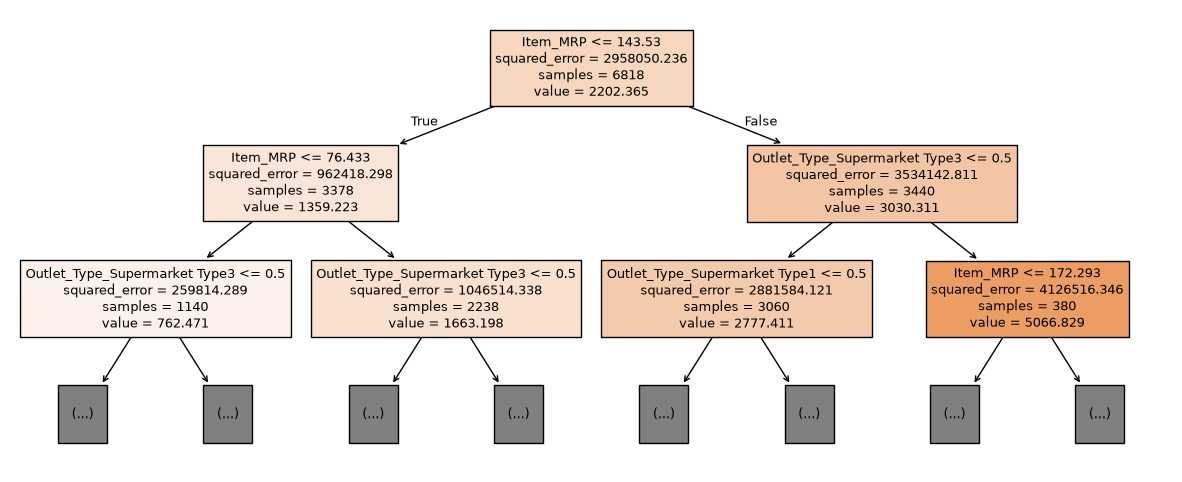

In [9]:
# The first 2 levels of the tree
plt.figure(figsize=(15, 6))
plot_tree(tree, max_depth=2, feature_names=list(X.columns), filled=True, fontsize=9)
plt.show()

---
**Step 4 takeaway**
- **What we did:** Tried tree depths 2 to 10, kept depth 5, and looked at which columns it uses.
- **Why:** Depth controls overfitting: deeper trees keep lowering the train error, but after depth 5 the validation error goes up.
- **What we learnt:** The tree beats the baseline (about 1,023 vs 1,069). Its top columns are **price** (importance 0.55) and **store type** (Type3 0.18, Type1 0.16). It splits on price first. For the more expensive half (MRP above 143.53) the next question is "Type3 store or not", and inside the Type3 branch it keeps splitting on price, with predicted sales jumping much more there. The cheaper half asks about price once more and then about Type3. So the store changes how much the price matters. Linear regression can't do that: it adds the same store effect at every price. Item type, weight, fat content and visibility are not in its top 5 columns.
---

## Step 5: Why the tree beats the baseline: sales = price x units

Sales are money, so sales = price x number of units sold (roughly, since items may not always sell at the full MRP). If a store sells more units, every extra 1 of price should add more sales in that store.
The scatter plot below checks this.

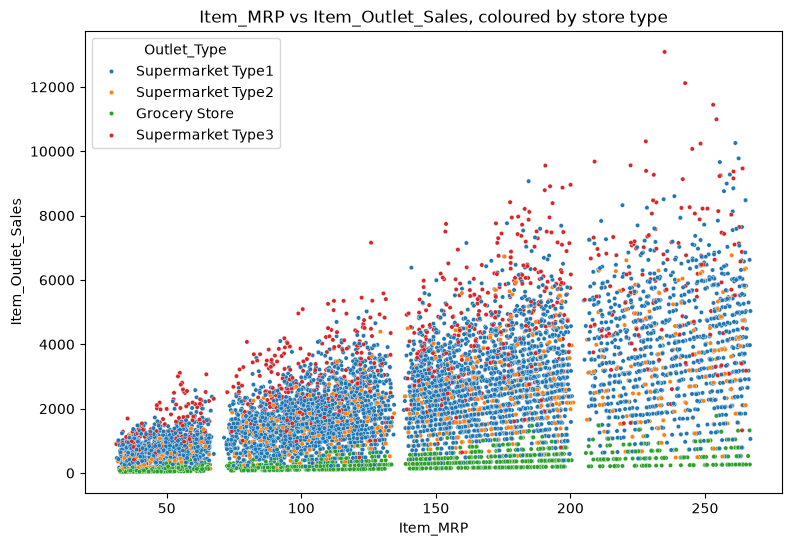

In [10]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=df["Item_MRP"], y=df["Item_Outlet_Sales"], hue=df["Outlet_Type"], s=10)
plt.title("Item_MRP vs Item_Outlet_Sales, coloured by store type")
plt.show()

In [11]:
# Sales divided by price = roughly how many units the item sold in that store.
# groupby works like GROUP BY in SQL:
# SELECT Outlet_Identifier, Outlet_Type, AVG(Sales_per_MRP) FROM df GROUP BY Outlet_Identifier, Outlet_Type
df["Sales_per_MRP"] = df["Item_Outlet_Sales"] / df["Item_MRP"]
units = df.groupby(["Outlet_Identifier", "Outlet_Type"])["Sales_per_MRP"].mean()
units.sort_values().round(2)

Outlet_Identifier  Outlet_Type      
OUT010             Grocery Store         2.38
OUT019             Grocery Store         2.44
OUT018             Supermarket Type2    13.85
OUT045             Supermarket Type1    15.58
OUT013             Supermarket Type1    16.00
OUT046             Supermarket Type1    16.19
OUT049             Supermarket Type1    16.63
OUT017             Supermarket Type1    16.66
OUT035             Supermarket Type1    16.97
OUT027             Supermarket Type3    26.61
Name: Sales_per_MRP, dtype: float64

---
**Step 5 takeaway**
- **What we did:** Plotted price against sales by store type, and worked out sales per 1 of price for each store.
- **Why:** To understand what the tree found, in a way we can turn into a simpler model.
- **What we learnt:** In the plot, grocery stores (green) stay flat near the bottom while Type3 (red) rises the fastest as the price goes up. The table agrees: the 2 grocery stores sell roughly 2.4 units of an item, most supermarkets about 14 to 17, and OUT027 (the only Type3) about 26.6. Each store **multiplies** the price by its own number.
---

## Step 6: Model 3: Store multiplier regression

We give linear regression one column per store. The column for a store holds the item's **MRP if the row is from that store, and 0 otherwise**.
Then the model learns one number per store: sales = about the coefficient of that store x MRP. That is 10 numbers in total.

- `fit_intercept=False`: no intercept, so the line goes through 0 (an item priced at 0 brings in no sales money). The cell after the multipliers checks that the data agrees.
- No `drop_first` here: every store needs its own multiplier. The dummy trap comes from 0/1 columns that always add up to 1 next to an intercept. Our columns hold prices and there is no intercept, so there is no trap.

In [12]:
# One 0/1 column per store
X3 = pd.get_dummies(df["Outlet_Identifier"], dtype=int)

# Multiply each column by the price: MRP if the row is from that store, 0 if not
for col in X3.columns:
    X3[col] = X3[col] * df["Item_MRP"]

X3.head()

,OUT010,OUT013,OUT017,OUT018,OUT019,OUT027,OUT035,OUT045,OUT046,OUT049
0,0.000,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,249.8092
1,0.000,0.0000,0.0,48.2692,0.0,0.0,0.0,0.0,0.0,0.0000
2,0.000,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,141.6180
3,182.095,0.0000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000
4,0.000,53.8614,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000


In [13]:
# Same split as before: same rows in the same order and the same random_state, so the same validation rows
X3_train, X3_val, y3_train, y3_val = train_test_split(X3, df["Item_Outlet_Sales"], test_size=0.2, random_state=42)

lr3 = LinearRegression(fit_intercept=False)
lr3.fit(X3_train, y3_train)
pred3 = lr3.predict(X3_val)

rmse = np.sqrt(mean_squared_error(y3_val, pred3))
mae = mean_absolute_error(y3_val, pred3)
r2 = r2_score(y3_val, pred3)
print(f"RMSE: {rmse:.1f} | MAE: {mae:.1f} | R²: {r2:.3f}")
results.append({"Model": "3. Store multiplier regression", "RMSE": rmse, "MAE": mae, "R2": r2})

RMSE: 1015.1 | MAE: 710.8 | R²: 0.621


In [14]:
# The 10 multipliers: extra sales for every 1 of MRP in each store
coef = pd.Series(lr3.coef_, index=X3.columns)
coef.sort_values().round(2)

OUT019     2.41
OUT010     2.48
OUT018    14.16
OUT045    15.70
OUT046    15.76
OUT017    16.66
OUT013    16.70
OUT049    16.92
OUT035    17.10
OUT027    26.33
dtype: float64

In [15]:
# Check: would an intercept help? We add a separate starting amount for every store
# (the 0/1 store columns), still with fit_intercept=False so the 0/1 columns don't fall into the dummy trap
X3b = X3.copy()
store_dummies = pd.get_dummies(df["Outlet_Identifier"], dtype=int, prefix="start")
for col in store_dummies.columns:
    X3b[col] = store_dummies[col]

X3b_train, X3b_val, y3b_train, y3b_val = train_test_split(X3b, df["Item_Outlet_Sales"], test_size=0.2, random_state=42)
lr3b = LinearRegression(fit_intercept=False)
lr3b.fit(X3b_train, y3b_train)
print(f"RMSE with an intercept for each store: {np.sqrt(mean_squared_error(y3b_val, lr3b.predict(X3b_val))):.1f}")

RMSE with an intercept for each store: 1014.8


---
**Step 6 takeaway**
- **What we did:** Built one "MRP in this store" column per store and fitted a linear regression without an intercept.
- **Why:** Step 5 showed each store multiplies the price by its own number. This model learns exactly those numbers.
- **What we learnt:** It has the lowest validation error so far (about 1,015) with only 10 numbers. Giving each store its own starting amount as well (20 numbers instead of 10) barely changes the error (last cell), so the simpler line through 0 is enough. The multipliers match Step 5: about 2.4 to 2.5 for the grocery stores, about 26 for OUT027, and about 14 to 17 for the rest.
---

## Step 7: Final model: averaging two estimates of each multiplier

We now have **two ways** to measure each store's multiplier:
- **Regression** (Step 6): least squares. Because errors are squared, expensive items (big sales) pull the line the most.
- **Average** (the Step 5 idea): the plain average of sales / MRP over the store's items. Every item counts equally.

Both measure the same number, and each has a little noise. Averaging two estimates of the same thing is a simple way to reduce that noise (the same idea as a random forest averaging many trees).
So the final model is: **predicted sales = (regression multiplier + average multiplier) / 2 x Item_MRP**. Still 10 numbers.

In [16]:
# Use only the training part of the split, so the validation rows stay unseen
train_rows = df.loc[X3_train.index]
val_rows = df.loc[X3_val.index]

average = train_rows.groupby("Outlet_Identifier")["Sales_per_MRP"].mean()
multipliers = pd.DataFrame({"regression": coef, "average": average})
multipliers["final"] = (multipliers["regression"] + multipliers["average"]) / 2
multipliers.sort_values("final").round(2)

,regression,average,final
OUT019,2.41,2.45,2.43
OUT010,2.48,2.42,2.45
OUT018,14.16,13.94,14.05
OUT045,15.70,15.74,15.72
OUT046,15.76,16.06,15.91
OUT013,16.70,16.35,16.53
OUT017,16.66,16.52,16.59
OUT049,16.92,16.57,16.75
OUT035,17.10,16.96,17.03
OUT027,26.33,26.63,26.48


In [17]:
# Prediction = the store's final multiplier x the item's MRP
# map() looks up each row's store in the multipliers table (like a lookup / JOIN in SQL)
pred_final = val_rows["Outlet_Identifier"].map(multipliers["final"]) * val_rows["Item_MRP"]

rmse = np.sqrt(mean_squared_error(y3_val, pred_final))
mae = mean_absolute_error(y3_val, pred_final)
r2 = r2_score(y3_val, pred_final)
print(f"RMSE: {rmse:.1f} | MAE: {mae:.1f} | R²: {r2:.3f}")
results.append({"Model": "4. Final: averaged store multipliers", "RMSE": rmse, "MAE": mae, "R2": r2})

RMSE: 1014.4 | MAE: 709.8 | R²: 0.621


---
**Step 7 takeaway**
- **What we did:** Worked out each store's multiplier in two ways (regression and plain average) and used the average of the two.
- **Why:** Both are fair estimates of the same number. Averaging them smooths out the noise in each one.
- **What we learnt:** The two estimates are very close for every store (the biggest gaps are about 0.35, for OUT013 and OUT049), which shows the multipliers are stable. The final model gives the lowest validation error (about 1,014.4).
---

## Step 8: Compare the models

In [18]:
results_df = pd.DataFrame(results)
results_df.round(3)

,Model,RMSE,MAE,R2
0,"1. Linear regression, all columns",1069.084,791.636,0.579
1,"2. Decision tree, depth 5",1023.266,719.045,0.615
2,3. Store multiplier regression,1015.118,710.815,0.621
3,4. Final: averaged store multipliers,1014.441,709.812,0.621


One validation split could be lucky. **5-fold cross-validation** (`cross_val_score`) splits the training data into 5 parts and uses each part once as the validation set, so every row is tested once.
`scoring="neg_root_mean_squared_error"` gives the RMSE as a negative number (sklearn always treats bigger as better), so we put a minus in front.

In [19]:
cv1 = cross_val_score(LinearRegression(), X, y, cv=5, scoring="neg_root_mean_squared_error")
cv2 = cross_val_score(DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=42), X, y,
                      cv=5, scoring="neg_root_mean_squared_error")
cv3 = cross_val_score(LinearRegression(fit_intercept=False), X3, df["Item_Outlet_Sales"],
                      cv=5, scoring="neg_root_mean_squared_error")
print(f"Model 1 average RMSE: {-cv1.mean():.1f}")
print(f"Model 2 average RMSE: {-cv2.mean():.1f}")
print(f"Model 3 average RMSE: {-cv3.mean():.1f}")

# The RMSE of each of the 5 folds, to see if the gap is bigger than the fold-to-fold changes
print("Model 2 folds:", (-cv2).round(1))
print("Model 3 folds:", (-cv3).round(1))

Model 1 average RMSE: 1132.6
Model 2 average RMSE: 1085.9
Model 3 average RMSE: 1072.6
Model 2 folds: [1104.8 1083.9 1084.6 1070.  1086. ]
Model 3 folds: [1088.1 1066.9 1066.  1066.6 1075.2]


In [20]:
# Would a random forest (many trees averaged, from the notes) do better?
# Same leaf size as our tree, one level deeper (averaging many trees lowers overfitting), 100 trees
rf = RandomForestRegressor(n_estimators=100, max_depth=6, min_samples_leaf=50, random_state=42)
cv4 = cross_val_score(rf, X, y, cv=5, scoring="neg_root_mean_squared_error")
print(f"Random forest average RMSE: {-cv4.mean():.1f}")
print("Random forest folds:", (-cv4).round(1))

Random forest average RMSE: 1079.6
Random forest folds: [1094.8 1078.1 1074.1 1067.2 1083.9]


In [21]:
# cross_val_score only works with a single sklearn model, so for the final model we do the same
# 5 folds ourselves. KFold(n_splits=5) cuts the rows into the same 5 parts that cv=5 used above.
kf = KFold(n_splits=5)
fold_rmse = []
for train_idx, val_idx in kf.split(df):
    tr = df.iloc[train_idx]
    va = df.iloc[val_idx]

    reg = LinearRegression(fit_intercept=False)
    reg.fit(X3.iloc[train_idx], tr["Item_Outlet_Sales"])
    avg = tr.groupby("Outlet_Identifier")["Sales_per_MRP"].mean()
    final_mult = (pd.Series(reg.coef_, index=X3.columns) + avg) / 2

    pred = va["Outlet_Identifier"].map(final_mult) * va["Item_MRP"]
    fold_rmse.append(np.sqrt(mean_squared_error(va["Item_Outlet_Sales"], pred)))

print(f"Final model average RMSE: {np.mean(fold_rmse):.1f}")
print("Final model folds:", np.round(fold_rmse, 1))

Final model average RMSE: 1072.2
Final model folds: [1086.6 1065.8 1065.3 1068.  1075.2]


---
**Step 8 takeaway**
- **What we did:** Put the validation scores in one table and checked them again with 5-fold cross-validation.
- **Why:** To pick the best model, and to make sure the ranking isn't luck from one split.
- **What we learnt:** The final model has the lowest error on the split (1,014.4) and in cross-validation (1,072.2). It beats the decision tree in all 5 folds and the random forest in 4 of 5. The step from Model 3 (1,072.6) to the final model is small, as expected, because both use the same idea; averaging just makes the multipliers a bit steadier. All folds are above 1,014.4, so our validation split was a bit easier than average. The random forest (1,079.6) beats the single tree but not the multiplier models, and it is much harder to explain.
---

## Step 9: Check the errors (post-model assumptions)

From the notes: the errors should be roughly normal, there should be no autocorrelation, and the spread should be constant (homoscedasticity).

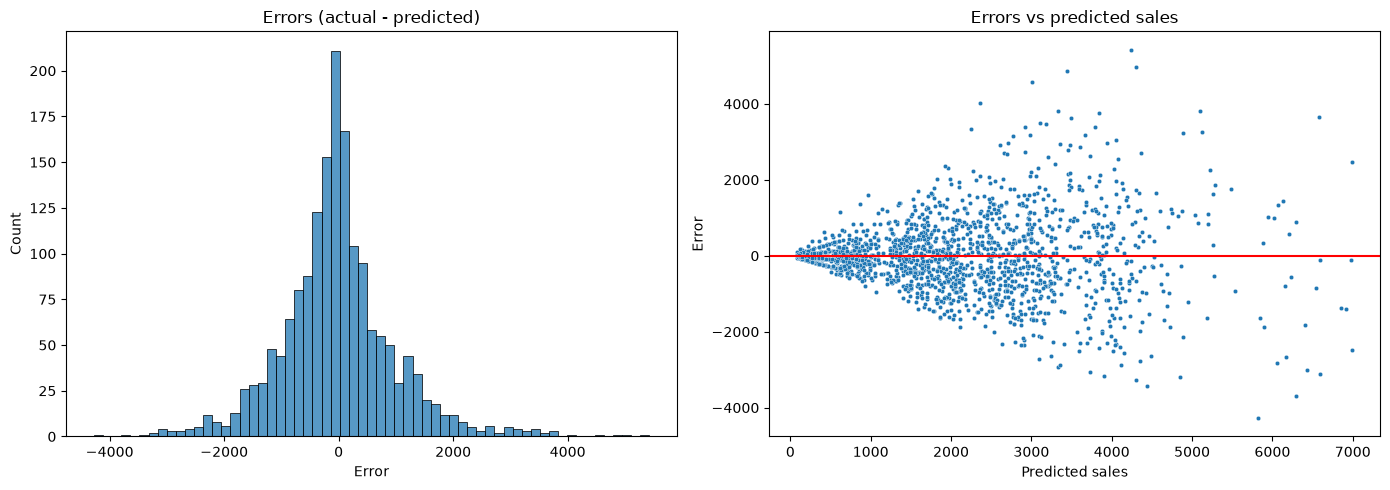

Average error: -22.7


In [22]:
residuals = y3_val - pred_final   # error = actual - predicted

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.histplot(residuals)
plt.xlabel("Error")
plt.title("Errors (actual - predicted)")

plt.subplot(1, 2, 2)
sns.scatterplot(x=pred_final, y=residuals, s=10)
plt.axhline(0, color="red")   # a line at error = 0
plt.xlabel("Predicted sales")
plt.ylabel("Error")
plt.title("Errors vs predicted sales")
plt.tight_layout()
plt.show()

print(f"Average error: {residuals.mean():.1f}")

---
**Step 9 takeaway**
- **What we did:** Plotted the errors of the final model, and the errors against the predictions.
- **Why:** To check the post-model assumptions from the notes.
- **What we learnt:** The errors are centred close to 0 (no bias) and roughly bell-shaped with a longer right tail. The spread gets wider for bigger predictions (a fan), so homoscedasticity is **not** fully met. That is natural here: a store selling 26 units varies more than one selling 2. It makes the errors bigger for expensive items, but it doesn't push the predictions up or down. Autocorrelation (Durbin-Watson) is for data in time order. Our rows are products, not dates, so it doesn't apply.
---

## Step 10: Final model on all the data, and the submission file

In [23]:
# Work out the final multipliers again, now from ALL 8,523 training rows (more data = better multipliers)
final_reg = LinearRegression(fit_intercept=False)
final_reg.fit(X3, df["Item_Outlet_Sales"])

final_multipliers = pd.DataFrame({"regression": pd.Series(final_reg.coef_, index=X3.columns),
                                  "average": df.groupby("Outlet_Identifier")["Sales_per_MRP"].mean()})
final_multipliers["final"] = (final_multipliers["regression"] + final_multipliers["average"]) / 2
final_multipliers.sort_values("final").round(2)

,regression,average,final
OUT010,2.44,2.38,2.41
OUT019,2.42,2.44,2.43
OUT018,14.17,13.85,14.01
OUT045,15.56,15.58,15.57
OUT046,15.90,16.19,16.05
OUT013,16.42,16.00,16.21
OUT049,16.81,16.63,16.72
OUT017,16.84,16.66,16.75
OUT035,17.09,16.97,17.03
OUT027,26.25,26.61,26.43


In [24]:
# Prediction for every test row = its store's final multiplier x its MRP
test["Item_Outlet_Sales"] = test["Outlet_Identifier"].map(final_multipliers["final"]) * test["Item_MRP"]
test["Item_Outlet_Sales"].describe()

count    5681.000000
mean     2180.448884
std      1334.540072
min        78.021004
25%      1073.368876
50%      2059.025849
75%      3027.307588
max      7005.031332
Name: Item_Outlet_Sales, dtype: float64

In [25]:
# The leaderboard wants exactly these 3 columns
submission = test[["Item_Identifier", "Outlet_Identifier", "Item_Outlet_Sales"]]
submission.to_csv("bigmart_submission.csv", index=False)
submission.shape

(5681, 3)

---
**Step 10 takeaway**
- **What we did:** Worked out the final 10 multipliers from all the training rows, predicted the test rows, and saved `bigmart_submission.csv`.
- **Why:** The leaderboard scores this file.
- **What we learnt:** 5,681 predictions, and none are negative (every multiplier and every price is positive; the smallest prediction is 78.0). The model only needs `Item_MRP` and `Outlet_Identifier`, which have no missing values in the test file, so the test data needs no cleaning.
---

## Step 11: Leaderboard score

We uploaded `bigmart_submission.csv` to the Analytics Vidhya Big Mart Sales Prediction practice problem.

**Public leaderboard RMSE: 1,149.25** (rank 770 of about 7,400 entries on 16 October 2026, roughly the top 10%)

This is higher than our 5-fold cross-validation RMSE (1,072.2). That doesn't mean we overfitted: even the best genuine entries on the leaderboard score about 1,122, so the test rows are simply harder to predict than the training rows for every model. The leaderboard is also very tight (rank 200 is about 1,145), so our rank is a fairer comparison than the raw number.

## Summary

### 1. What we did
- Started from the cleaned data of the EDA notebook and split it 80/20 into train and validation.
- Compared models step by step: linear regression on all columns, a decision tree, a store multiplier regression, and the final model, which averages two estimates of each store's multiplier. Checked the ranking with 5-fold cross-validation, and also tried a random forest.
- Retrained the final model on all the data and submitted the test predictions.

### 2. Results

| Model | Validation RMSE | 5-fold CV RMSE |
|---|---|---|
| 1. Linear regression, all columns | 1,069.1 | 1,132.6 |
| 2. Decision tree, depth 5 | 1,023.3 | 1,085.9 |
| Random forest (check only) | | 1,079.6 |
| 3. Store multiplier regression | 1,015.1 | 1,072.6 |
| 4. Final: averaged store multipliers | **1,014.4** | **1,072.2** |

- The final model is just **10 numbers**, one per store: predicted sales = store multiplier x Item_MRP.
- Public leaderboard RMSE: **1,149.25**, rank 770 of about 7,400 (Step 11).

### 3. What this means for BigMart
- **The store matters more than the product.** For the same item at the same price, OUT027 (Supermarket Type3) sells about 11 times as much as a grocery store (multipliers of about 26.4 vs 2.4).
- **Price works through the store.** Every extra 1 of MRP adds about 26 in sales at OUT027 but only about 2.4 in a grocery store. Higher-priced items pay off most in the big supermarkets, so that is where they should be stocked and promoted first.
- **Grocery stores (OUT010, OUT019) sell very little.** Turning them into the supermarket format, or finding out why Type3 does so well, matters more than changing the product mix.
- These are patterns in 2013 data, not proof of cause. For example, OUT027 may sell more because of its location or size, not only its format.

### 4. Limitations
- The final model uses only 2 columns. The tree barely used item type, weight, fat content or visibility (Step 4), and some items may simply be more popular than others, which the model can't see.
- The errors spread out more for big sales (Step 9), so predictions for expensive items in big stores are the least precise.
- There is one Type3 store and one Type2 store, so "store type" and "store" are the same thing for them.
- It cannot predict a brand-new store, because every store needs its own multiplier.